Importações

In [ ]:
import numpy as np
import random
import math
import matplotlib.pyplot as plt
import pandas as pd
from prettytable import PrettyTable
import hashlib
import importlib
import inspect
import multiprocessing as mp
import os
from pathlib import Path
import sys
from tempfile import TemporaryDirectory
from uuid import uuid4
from concurrent.futures import ProcessPoolExecutor, wait, FIRST_COMPLETED

Funções

In [2]:
def inicializar_pesos(n_entradas, intervalo=(-0.5, 0.5)):
    pesos = np.random.uniform(intervalo[0], intervalo[1], n_entradas + 1)
    return pesos

def degrau(z):
    return 1 if z>=0 else 0

def prever(exemplo, pesos):
    z = np.dot(exemplo, pesos[1:]) + pesos[0] 
    return degrau(z)

def treinar_perceptron(X, Y, taxa_aprendizado=0.1, pesos_iniciais=None, progresso_a_cada=None):
    num_amostras, num_entradas = X.shape

    if pesos_iniciais is None:
        pesos = inicializar_pesos(num_entradas)
    else:
        pesos = pesos_iniciais.copy()

    epocas = 0
    total_ajustes = 0
    convergiu = False

    while not convergiu:
        erros_na_epoca = 0
        epocas += 1

        inicio = 0
        while inicio < num_amostras:
            # Localizar o primeiro erro no trecho ainda não visitado da época.
            # Exemplos corretos não alteram os pesos e podem ser pulados.
            z = X[inicio:] @ pesos[1:] + pesos[0]
            erros = (z >= 0) != Y[inicio:]
            primeiro_erro = int(np.argmax(erros))
            if not erros[primeiro_erro]:
                break

            i = inicio + primeiro_erro
            x_i = X[i]
            erro = Y[i] - int(z[primeiro_erro] >= 0)

            pesos[0] += taxa_aprendizado * erro         # ATUALIZA BIAS
            pesos[1:] += taxa_aprendizado * erro * x_i  # ATUALIZA PESOS
            total_ajustes += 1
            erros_na_epoca += 1
            inicio = i + 1

       
        if progresso_a_cada is not None and epocas % progresso_a_cada == 0:
            print(
                f'Época {epocas}: {total_ajustes} ajustes acumulados; '
                f'{erros_na_epoca} ajustes nesta época.',
                flush=True,
            )

        if erros_na_epoca == 0:
            convergiu = True

    return pesos, epocas, total_ajustes


COLETA DOS DADOS

In [3]:

dados = np.load('dados/dataAll20262.txt', allow_pickle=True)

print("Dados carregados com sucesso! Formato:", dados.shape)


if dados.ndim == 3:
    dados = dados.squeeze(axis=1) # Transforma (m, 1, 3) em (m, 3)

X = dados[:, :2]  
Y = dados[:, 2]   

Dados carregados com sucesso! Formato: (1000, 1, 3)


TREINAMENTO

Vetor inicial de pesos (incluindo bias): [-0.12545988  0.45071431  0.23199394]

--- RESULTADOS DO TREINAMENTO ---
Número de épocas até a convergência: 3
Número total de ajustes no vetor de pesos: 42
Pesos finais otimizados: [  -0.52545988   77.49164736 -385.93744796]


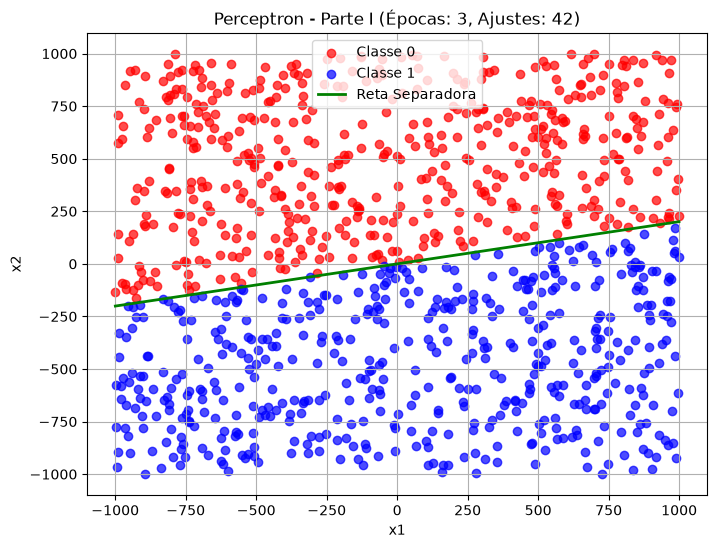

In [4]:
TAXA_APRENDIZADO = 0.1


np.random.seed(42) #SEMENTE DE ALEATORIEDADE 
pesos_iniciais = inicializar_pesos(X.shape[1])

print("Vetor inicial de pesos (incluindo bias):", pesos_iniciais)

# TREINAMENTO
pesos_finais, total_epocas, total_ajustes = treinar_perceptron(X, Y, TAXA_APRENDIZADO, pesos_iniciais)

print(f"\n--- RESULTADOS DO TREINAMENTO ---")
print(f"Número de épocas até a convergência: {total_epocas}")
print(f"Número total de ajustes no vetor de pesos: {total_ajustes}")
print(f"Pesos finais otimizados: {pesos_finais}")


# CLASSES
classe_0 = X[Y == 0]
classe_1 = X[Y == 1]

plt.figure(figsize=(8, 6))

# DEFININDO PADRÃO E CORES
plt.scatter(classe_0[:, 0], classe_0[:, 1], color='red', label='Classe 0', alpha=0.7)
plt.scatter(classe_1[:, 0], classe_1[:, 1], color='blue', label='Classe 1', alpha=0.7)

# COEFICIENTES DA RETA SEPARADORA
b = pesos_finais[0]
w1 = pesos_finais[1]
w2 = pesos_finais[2]

# LIMITE DO EIXO X
x1_min, x1_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
x1_valores = np.array([x1_min, x1_max])

# CALCULANDO OS VALORES DE x2 PARA A RETA SEPARADORA
if w2 != 0:
    x2_valores = (-w1 * x1_valores - b) / w2
    plt.plot(x1_valores, x2_valores, color='green', linewidth=2, label='Reta Separadora')
elif w1 != 0:
    plt.axvline(-b / w1, color='green', linewidth=2, label='Reta Separadora')

plt.xlabel('x1')
plt.ylabel('x2')
plt.title(f'Perceptron - Parte I (Épocas: {total_epocas}, Ajustes: {total_ajustes})')
plt.legend()
plt.grid(True)
plt.show()

# Parte II — Experimentação

As matrículas da equipe são **2315310042, 2315310013 e 2315310024**.
A soma dos últimos dígitos é 2 + 3 + 4 = 9; o identificador é
**9 % 4 = 1**. Portanto, os experimentos usam `dados/data120262.txt`.

Reutilizamos o treinamento da Parte I nas seis combinações das taxas
de aprendizado **0,4; 0,1; 0,01** com os intervalos de inicialização
**(−100, +100)** e **(−0,5, +0,5)**. Cada combinação é executada
**10 vezes**, totalizando **60 treinamentos**.

In [ ]:
MATRICULAS = np.array([2315310042, 2315310013, 2315310024], dtype=np.int64)
IDENTIFICADOR_EQUIPE = int(np.sum(MATRICULAS % 10) % 4)
arquivo_parte_II = f'dados/data{IDENTIFICADOR_EQUIPE}20262.txt'

dados_II = np.load(arquivo_parte_II, allow_pickle=False)
dados_II = dados_II.squeeze(axis=1)
X_II = dados_II[:, :2]
Y_II = dados_II[:, 2].astype(np.int64)

print(f'Identificador da equipe: {IDENTIFICADOR_EQUIPE}')
print(f'Arquivo: {arquivo_parte_II}')
print(f'Exemplos: {X_II.shape[0]}; entradas por exemplo: {X_II.shape[1]}')
print(f'Classe 0: {np.count_nonzero(Y_II == 0)} exemplos')
print(f'Classe 1: {np.count_nonzero(Y_II == 1)} exemplos')

Identificador da equipe: 1
Arquivo: dados/data120262.txt
Exemplos: 1000; entradas por exemplo: 2
Classe 0: 446 exemplos
Classe 1: 554 exemplos


## Execução dos experimentos

A Parte II não exige uma semente específica. Escolhemos o identificador
da equipe como semente para permitir a reprodução dos resultados.
Ela é definida **uma única vez antes dos experimentos**: cada repetição
recebe um novo vetor de pesos aleatórios, incluindo o bias, dentro do
intervalo da configuração.

Mantemos a ordem dos exemplos, a função degrau com limiar zero e a
atualização de pesos da Parte I. Uma atualização conjunta do bias e
dos pesos conta como **um ajuste**. O número de épocas inclui a última
passagem sem ajustes, que confirma a convergência. Após cada treinamento,
verificamos se todos os exemplos foram classificados corretamente.


O treinamento usa NumPy para localizar o próximo exemplo incorreto na época.
Após cada ajuste, recalcula as saídas do trecho restante. Isso preserva a
ordem de apresentação e as atualizações sequenciais do Perceptron, evitando
percorrer em Python os exemplos que não exigem ajuste.


As entradas permanecem na escala original do arquivo. As repetições
independentes rodam em até oito processos. Os pesos são sorteados antes
da execução em paralelo; cada repetição mantém a mesma ordem dos
exemplos e a mesma regra de atualização. A execução em paralelo
reduz o tempo total, sem mudar as estatísticas de cada treinamento.

Cada resultado concluído é salvo em um checkpoint local na pasta
`.ipynb_checkpoints`. Ao executar novamente, são recuperadas apenas
as repetições concluídas com os mesmos dados, pesos e algoritmo.
Para repetir todos os treinamentos, remova `parte_II_experimentos.npz`
dessa pasta antes de executar a célula.


In [ ]:

TAXAS_II = (0.4, 0.1, 0.01)
INTERVALOS_II = ((-100.0, 100.0), (-0.5, 0.5))
REPETICOES_II = 10
configuracoes_II = [(taxa, intervalo) for taxa in TAXAS_II for intervalo in INTERVALOS_II]
nomes_II = [f'C{i + 1}' for i in range(len(configuracoes_II))]
formato_II = (len(configuracoes_II), REPETICOES_II)
ajustes_II = np.full(formato_II, -1, dtype=np.int64)
epocas_II = np.full(formato_II, -1, dtype=np.int64)
erros_finais_II = np.full(formato_II, -1, dtype=np.int64)
concluidas_II = np.zeros(formato_II, dtype=bool)
pesos_iniciais_II = np.empty(formato_II + (X_II.shape[1] + 1,))
pesos_finais_II = np.full_like(pesos_iniciais_II, np.nan)

np.random.seed(IDENTIFICADOR_EQUIPE)
for i, (_, intervalo) in enumerate(configuracoes_II):
    for repeticao in range(REPETICOES_II):
        pesos_iniciais_II[i, repeticao] = inicializar_pesos(X_II.shape[1], intervalo)

def executar_repeticao(argumentos):
    i, repeticao, X_local, Y_local, taxa, w_inicial = argumentos
    w_final, n_epocas, n_ajustes = treinar_perceptron(
        X_local, Y_local, taxa_aprendizado=taxa, pesos_iniciais=w_inicial,
    )
    previsoes = (X_local @ w_final[1:] + w_final[0] >= 0).astype(np.int64)
    n_erros = int(np.count_nonzero(previsoes != Y_local))
    assert n_erros == 0, f'C{i + 1}, repetição {repeticao + 1}: erro após convergência.'
    return i, repeticao, w_final, n_epocas, n_ajustes, n_erros

assinatura_II = hashlib.sha256(
    X_II.tobytes() + Y_II.tobytes() + pesos_iniciais_II.tobytes()
    + str((configuracoes_II, formato_II, X_II.shape, np.__version__)).encode()
    + inspect.getsource(treinar_perceptron).encode()
).hexdigest()
checkpoint_II = Path('.ipynb_checkpoints/parte_II_experimentos.npz')
checkpoint_II.parent.mkdir(exist_ok=True)

if checkpoint_II.exists():
    with np.load(checkpoint_II, allow_pickle=False) as salvo:
        if salvo['assinatura'].item() == assinatura_II:
            ajustes_II[:] = salvo['ajustes']
            epocas_II[:] = salvo['epocas']
            erros_finais_II[:] = salvo['erros_finais']
            pesos_finais_II[:] = salvo['pesos_finais']
            concluidas_II[:] = salvo['concluidas']
            # Revalidar também as previsões de cada resultado recuperado.
            for i, repeticao in np.argwhere(concluidas_II):
                w = pesos_finais_II[i, repeticao]
                assert np.all((X_II @ w[1:] + w[0] >= 0) == Y_II)

def salvar_checkpoint_II():
    temporario = checkpoint_II.with_suffix('.tmp.npz')
    np.savez(
        temporario, assinatura=assinatura_II, ajustes=ajustes_II,
        epocas=epocas_II, erros_finais=erros_finais_II,
        pesos_finais=pesos_finais_II, concluidas=concluidas_II,
    )
    temporario.replace(checkpoint_II)

tarefas_II = [
    (i, repeticao, X_II, Y_II, taxa, pesos_iniciais_II[i, repeticao])
    for i, (taxa, _) in enumerate(configuracoes_II)
    for repeticao in range(REPETICOES_II)
    if not concluidas_II[i, repeticao]
]
PROCESSOS_II = min(8, os.cpu_count() or 1)
print(f'Concluídas no checkpoint: {np.count_nonzero(concluidas_II)}/{concluidas_II.size}.', flush=True)

if tarefas_II:
    with TemporaryDirectory(prefix='rna-perceptron-') as pasta:
        nome_modulo = f'_rna_perceptron_{uuid4().hex}'
        codigo_modulo = '\n\n'.join([
            'import numpy as np',
            inspect.getsource(inicializar_pesos),
            inspect.getsource(treinar_perceptron),
            inspect.getsource(executar_repeticao),
        ])
        Path(pasta, nome_modulo + '.py').write_text(codigo_modulo, encoding='utf-8')
        sys.path.insert(0, pasta)
        try:
            modulo = importlib.import_module(nome_modulo)
            print(f'Executando {len(tarefas_II)} repetições com {PROCESSOS_II} processos.', flush=True)
            with ProcessPoolExecutor(
                max_workers=PROCESSOS_II, mp_context=mp.get_context('spawn'),
            ) as executor:
                pendentes = {
                    executor.submit(modulo.executar_repeticao, tarefa)
                    for tarefa in tarefas_II
                }
                while pendentes:
                    terminadas, pendentes = wait(
                        pendentes, timeout=30, return_when=FIRST_COMPLETED,
                    )
                    for futuro in terminadas:
                        i, repeticao, w, n_epocas, n_ajustes, n_erros = futuro.result()
                        pesos_finais_II[i, repeticao] = w
                        epocas_II[i, repeticao] = n_epocas
                        ajustes_II[i, repeticao] = n_ajustes
                        erros_finais_II[i, repeticao] = n_erros
                        concluidas_II[i, repeticao] = True
                        salvar_checkpoint_II()
                        print(
                            f'{nomes_II[i]}, repetição {repeticao + 1}: '
                            f'{n_epocas} épocas; {n_ajustes} ajustes; zero erros.',
                            flush=True,
                        )
                    print(
                        f'Concluídas: {np.count_nonzero(concluidas_II)}/{concluidas_II.size}.',
                        flush=True,
                    )
        finally:
            sys.path.remove(pasta)
            sys.modules.pop(nome_modulo, None)

assert np.all(concluidas_II) and np.all(erros_finais_II == 0)
print(f'Concluídos {ajustes_II.size} treinamentos até a convergência.')

Concluídas no checkpoint: 1/60.
Executando 59 repetições com 8 processos.
Concluídas: 1/60.
Concluídas: 1/60.
Concluídas: 1/60.
Concluídas: 1/60.
Concluídas: 1/60.
Concluídas: 1/60.
Concluídas: 1/60.
Concluídas: 1/60.
Concluídas: 1/60.
Concluídas: 1/60.
Concluídas: 1/60.
Concluídas: 1/60.
C1, repetição 6: 3521315 épocas; 15080005 ajustes; zero erros.
Concluídas: 2/60.
C1, repetição 3: 3520543 épocas; 15078600 ajustes; zero erros.
Concluídas: 3/60.
Concluídas: 3/60.
Concluídas: 3/60.
C1, repetição 4: 3513421 épocas; 15058849 ajustes; zero erros.
Concluídas: 4/60.
Concluídas: 4/60.
Concluídas: 4/60.
C1, repetição 5: 3521399 épocas; 15078216 ajustes; zero erros.
Concluídas: 5/60.
Concluídas: 5/60.
C1, repetição 2: 3515365 épocas; 15061950 ajustes; zero erros.
Concluídas: 6/60.
C1, repetição 9: 3528243 épocas; 15101912 ajustes; zero erros.
Concluídas: 7/60.
Concluídas: 7/60.
C1, repetição 8: 3515782 épocas; 15064043 ajustes; zero erros.
Concluídas: 8/60.
C1, repetição 7: 3529663 épocas; 15

## Tabela de resultados

Para cada configuração, calculamos a média e o desvio padrão da
quantidade de ajustes, além do mínimo e do máximo de épocas das dez
execuções. Usamos `np.std(..., ddof=0)`, o desvio padrão descritivo
das dez observações. O valor após **±** é esse desvio padrão,
e não um intervalo de confiança.

A tabela detalhada das 60 execuções está disponível em `resultados_II`;
os vetores de pesos estão em `pesos_iniciais_II` e `pesos_finais_II`.

In [7]:
intervalos_texto_II = [
    f'({intervalo[0]:g}, +{intervalo[1]:g})'
    for _, intervalo in configuracoes_II
]

resultados_II = pd.DataFrame({
    'Configuração': np.repeat(nomes_II, REPETICOES_II),
    'Taxa de aprendizado': np.repeat(
        np.array([taxa for taxa, _ in configuracoes_II]), REPETICOES_II
    ),
    'Intervalo de pesos': np.repeat(intervalos_texto_II, REPETICOES_II),
    'Repetição': np.tile(np.arange(1, REPETICOES_II + 1), len(configuracoes_II)),
    'Ajustes': ajustes_II.ravel(),
    'Épocas': epocas_II.ravel(),
    'Erros finais': erros_finais_II.ravel(),
})

resumo_II = pd.DataFrame({
    'Configuração': nomes_II,
    'Taxa de aprendizado': [taxa for taxa, _ in configuracoes_II],
    'Intervalo de pesos': intervalos_texto_II,
    'Média de ajustes': np.mean(ajustes_II, axis=1),
    'Desvio padrão de ajustes': np.std(ajustes_II, axis=1, ddof=0),
    'Mín. épocas': np.min(epocas_II, axis=1),
    'Máx. épocas': np.max(epocas_II, axis=1),
})

tabela_II = PrettyTable()
tabela_II.field_names = [
    'Configuração', 'Taxa (η)', 'Intervalo de pesos',
    'Ajustes (média ± desvio padrão)', 'Mín. épocas', 'Máx. épocas',
]
for linha in resumo_II.itertuples(index=False, name=None):
    nome, taxa, intervalo, media, desvio, minimo, maximo = linha
    tabela_II.add_row([
        nome, f'{taxa:g}', intervalo,
        f'{media:.2f} ± {desvio:.2f}', minimo, maximo,
    ])

print(tabela_II)

+--------------+----------+--------------------+---------------------------------+-------------+-------------+
| Configuração | Taxa (η) | Intervalo de pesos | Ajustes (média ± desvio padrão) | Mín. épocas | Máx. épocas |
+--------------+----------+--------------------+---------------------------------+-------------+-------------+
|      C1      |   0.4    |    (-100, +100)    |      15080935.60 ± 18613.54     |   3513421   |   3534896   |
|      C2      |   0.4    |    (-0.5, +0.5)    |      15083255.00 ± 13946.62     |   3517338   |   3531790   |
|      C3      |   0.1    |    (-100, +100)    |      15086348.60 ± 17859.23     |   3518149   |   3532482   |
|      C4      |   0.1    |    (-0.5, +0.5)    |      15075561.90 ± 16761.17     |   3511425   |   3530946   |
|      C5      |   0.01   |    (-100, +100)    |      15083134.60 ± 15952.36     |   3517468   |   3532147   |
|      C6      |   0.01   |    (-0.5, +0.5)    |      15084923.50 ± 12544.72     |   3515420   |   3530713   |
+

## Boxplots dos experimentos

O gráfico reúne as seis configurações, identificadas conforme a tabela,
para as duas medidas de esforço de treinamento: **ajustes** e **épocas**.
Em ambos os painéis, valores menores representam menos esforço.
As linhas laranja indicam as medianas e os triângulos pretos, as médias.
As caixas representam o intervalo entre o primeiro e o terceiro quartis;
os bigodes seguem o critério de 1,5 vezes esse intervalo. Pontos isolados
representam observações fora dos bigodes, não erros de classificação.

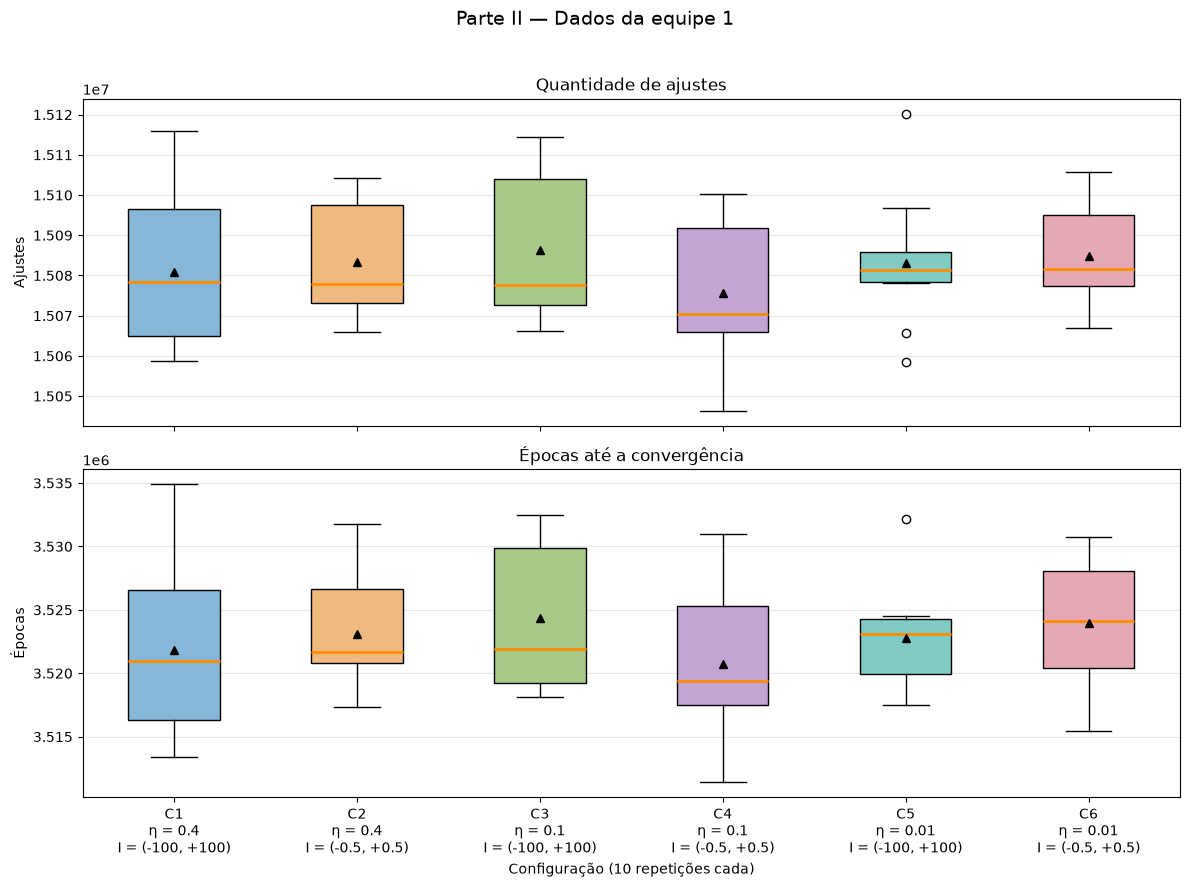

In [8]:
fig_II, eixos_II = plt.subplots(2, 1, figsize=(12, 9), sharex=True)
cores_II = ('#86b6d8', '#efba80', '#a9c989', '#c2a5d4', '#80cbc4', '#e5a8b4')

for eixo, medidas, titulo, unidade in (
    (eixos_II[0], ajustes_II, 'Quantidade de ajustes', 'Ajustes'),
    (eixos_II[1], epocas_II, 'Épocas até a convergência', 'Épocas'),
):
    caixas = eixo.boxplot(
        medidas.T,
        patch_artist=True,
        showmeans=True,
        medianprops={'color': 'darkorange', 'linewidth': 2},
        meanprops={'marker': '^', 'markerfacecolor': 'black', 'markeredgecolor': 'black'},
    )
    for caixa, cor in zip(caixas['boxes'], cores_II):
        caixa.set_facecolor(cor)
    eixo.set_title(titulo)
    eixo.set_ylabel(unidade)
    eixo.grid(axis='y', alpha=0.3)

eixos_II[1].set_xticks(np.arange(1, len(configuracoes_II) + 1))
eixos_II[1].set_xticklabels([
    f'{nome}\nη = {taxa:g}\nI = {intervalo}'
    for nome, (taxa, _), intervalo in zip(
        nomes_II, configuracoes_II, intervalos_texto_II
    )
])
eixos_II[1].set_xlabel('Configuração (10 repetições cada)')
fig_II.suptitle(f'Parte II — Dados da equipe {IDENTIFICADOR_EQUIPE}', fontsize=14)
fig_II.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

## Análise dos resultados

Todas as **60 execuções convergiram**, com **zero erros nos 1.000 exemplos**
do arquivo `data120262.txt`. Assim, as configurações atingiram o mesmo resultado
de classificação neste conjunto de treinamento. As diferenças discutidas aqui
são de **esforço de treinamento**, medido por ajustes e épocas.

Considerando a média de ajustes, **C4** (η = 0.1, I = (-0.5, +0.5)) apresentou o menor
valor observado: **15.075.561,90 ± 16.761,17 ajustes**.
**C3** (η = 0.1, I = (-100, +100)) apresentou o maior:
**15.086.348,60 ± 17.859,23 ajustes**.
Entre a maior e a menor média, a diferença foi de **10.786,70 ajustes**,
ou **0,07%** em relação à menor média.
Essa diferença é menor que o desvio padrão de cada uma dessas duas
configurações. Portanto, a menor média de C4 representa uma vantagem
descritiva pequena; isoladamente, ela não sustenta a afirmação de que C4
é superior às demais.

Quanto às épocas, **C4** (η = 0.1, I = (-0.5, +0.5)) apresentou a menor média,
**3.520.764,80 épocas**, com mínimo de
**3.511.425** e máximo de
**3.530.946**. A menor dispersão na quantidade de ajustes
foi observada em **C6** (η = 0.01, I = (-0.5, +0.5)), cujo desvio padrão foi
**12.544,72**. Esses critérios ajudam a comparar tanto o
custo quanto a variação entre execuções.

As caixas das configurações com menor e maior média de ajustes se sobrepõem. Isso mostra que uma comparação baseada apenas nas médias precisa ser interpretada junto à variabilidade das execuções. A média, a mediana e a dispersão nos boxplots devem ser
consideradas em conjunto. Uma taxa de aprendizado maior não garante menos
ajustes: as decisões do degrau dependem do sinal da combinação linear, e a
taxa interage com a escala dos pesos iniciais.

**Conclusão:** as configurações tiveram custos muito próximos e forte
sobreposição nos boxplots. Todas resolveram o problema de classificação.
Os resultados não evidenciam uma configuração claramente melhor ou pior
que as demais neste experimento, embora C4 tenha a menor média observada. Com dez repetições por
configuração, um único conjunto de dados e sem um teste estatístico, os
boxplots e as médias não permitem afirmar superioridade universal nem
equivalência estatística entre as configurações.


### Por que foram necessárias tantas épocas?

As entradas do arquivo chegam perto de ±1.000, enquanto a entrada do bias
é constante e igual a 1. Na regra de aprendizado, o ajuste do bias é
`η × erro`, e o dos demais pesos é `η × erro × entrada`. Para uma entrada
de 1.000 e η = 0,4, por exemplo, os ajustes podem ser 400 no peso da entrada
e 0,4 no bias. Essa diferença de escala prejudica a velocidade de aprendizado
do deslocamento da reta. Mantivemos as entradas originais nos experimentos.

A implementação otimizada foi comparada com a original: após 10.000 épocas
da primeira repetição de C1, os pesos e os 347.954 ajustes eram exatamente
iguais. Todas as 60 soluções finais foram verificadas contra os 1.000 exemplos.
